In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append('..')
from Synthetic.index import SyntheticGenerator

# CALIBRAÇÃO
- O notebook transforma o **perfil sem rótulo** de um bloco (`1 - Profile`, em `files/<bloco>/profile.pkl`) na configuração do `SyntheticGenerator.dataset()`
- Primeiro a **parte medida** (M4): o que o perfil mede direto vira parâmetro por conta, sem busca. Depois a busca do que não se mede (AG do `Synthetic/Nature`), que parte do ponto medido
- Roda igual em qualquer bloco: só muda `BLOCK`. O mapa frequência nominal → período (`files/period_map.csv`) é do gerador, não do bloco, e vem do `1 - Profile`
- Nada aqui usa a interpretação do especialista

In [2]:
BLOCK        = 'marlim'
OUTPUT       = f'files/{BLOCK}'
N_IMAGES     = 220                                # TILES DO DATASET (O TAMANHO DO dataset_74)
BAND         = 250                                # ALTURA DAS FAIXAS DE z, A MESMA DO PERFIL
MIN_SHARE    = 0.05                               # FAIXA COM MENOS DISSO DOS TILES VIVOS NÃO VIRA REGIÃO
LIVE_TILE    = 0.8                                # TILE VIVO: FRAÇÃO DA SEÇÃO COM REFLETOR (O PERÍODO SÓ É MEDIDO NELE)
DEAD_TILE    = 0.5                                # TILE COM MENOS DISSO VIVO CONTA COMO ZONA MORTA NA COLUNA DA FAIXA
SEAFLOOR_MIN = 0.05                               # UM POUCO DE FUNDO DO MAR EM TODA REGIÃO: A REDE APRENDE QUE A ÁGUA NÃO É FALHA
SEED         = 20261022

# O QUE O PERFIL NÃO MEDE: PONTO DE PARTIDA DA BUSCA (O C3_m4full DE 22/10: FALHAS SUTIS, LENTES, CORPOS COM CAMADAS, BORDAS, SATURAÇÃO)
BASE = {'noiseLevel': (0.0, 0.15), 'faultCount': (2, 8), 'faultThrowPeriod': (0.2, 1.5), 'faultVisible': 0.15, 'faultDrag': (0.0, 0.8), 'bodyCount': (0, 3), 'bodyLayers': 0.5, 'lensSigma': (8, 50), 'lensCut': (0.0, 0.5), 'lensEdge': (0.3, 2.0), 'lensThick': 3.0, 'gainField': 0.4, 'waveletPhase': (-90.0, 90.0), 'deadZoneHatch': (0.05, 0.2), 'deadTraceProb': 0.2, 'gain': 1.0, 'gainJitter': 0.4, 'clip': 2.4}

# PERFIL
- Uma linha por tile do bloco: posição do núcleo (`z`), fração de água e de seção viva e os descritores da régua (período, contraste, mergulho, continuidade, ruído fino)
- O mapa do gerador dá, para cada frequência nominal do Ricker, o período que a **mesma régua** mede no tile sintético

In [3]:
profile          = pd.read_pickle(f'{OUTPUT}/profile.pkl')
periodMap        = pd.read_csv('files/period_map.csv')
profile['faixa'] = (profile.z // BAND * BAND).astype(int)

table = profile.groupby('faixa').agg(tiles=('z', 'size'), agua=('water', lambda s: (s > 0.5).mean()), vivo=('live', lambda s: (s >= LIVE_TILE).mean()), periodo=('period', 'median'))
table.round(2)

,tiles,agua,vivo,periodo
faixa,,,,
0,560,0.90,0.07,4.16
250,560,0.17,0.75,4.64
500,560,0.00,0.58,10.12
750,560,0.00,0.72,19.01
1000,560,0.00,0.42,21.34
1250,420,0.00,0.01,23.26
1500,420,0.03,0.00,NaN


# PARTE MEDIDA (M4)
- **Regiões:** uma por faixa de z que tem pelo menos `MIN_SHARE` dos tiles vivos (água ≤ 80%, viva ≥ `LIVE_TILE`), com peso proporcional ao número deles. A faixa de quase só água (topo) e as de zona morta (base) não viram região: o que a rede precisa ver delas entra pela coluna
- **Período → `waveletFreq`:** o p10–p90 do período dos tiles vivos da faixa, traduzido pelo mapa do gerador (interpolação em log; fora do mapa, a borda). É a medida que mais pesa: o período do Marlim vai de ~4 px no raso a ~25 px no fundo, e o dataset padrão cobre só ~18% dele
- **Coluna:** `deadZoneProb` = fração dos tiles da faixa (fora da água) com menos de `DEAD_TILE` vivo; `seafloorProb` = fração dos tiles com água na faixa que contém o fundo do mar e `SEAFLOOR_MIN` nas outras
- O resto da configuração vem do `BASE`

In [4]:
# AS REGIÕES DO dataset() PELO PERFIL: UMA POR FAIXA DE z COM TILES VIVOS SUFICIENTES, COM O PESO DELA, O PERÍODO p10–p90 EM waveletFreq E A COLUNA
class RegionBuilder:
    def __init__(self, profile, periodMap, nImages, band=250, minShare=0.05):
        self.profile   = profile
        self.periodMap = periodMap
        self.nImages   = nImages
        self.band      = band
        self.minShare  = minShare

    def update(self):
        live        = self.profile[(self.profile.water <= 0.8) & (self.profile.live >= LIVE_TILE) & self.profile.period.notna()]
        self.groups = {z: g for z, g in live.groupby((live.z // self.band) * self.band) if len(g) >= self.minShare * len(live)}
        total       = sum(len(g) for g in self.groups.values())
        self.counts = {z: int(round(self.nImages * len(g) / total)) for z, g in self.groups.items()}
        self.counts[max(self.counts, key=self.counts.get)] += self.nImages - sum(self.counts.values())
        self.curve  = self.periodMap.groupby('f').period.median().sort_values()

    def getFreq(self, period):
        return round(float(np.exp(np.interp(np.log(period), np.log(self.curve.values), np.log(self.curve.index.values)))), 1)

    def getColumn(self, z):
        band  = self.profile[(self.profile.z // self.band) * self.band == z]
        rock  = band[band.water <= 0.8]
        floor = float((rock.water > 0.02).mean()) if (band.water > 0.5).any() else SEAFLOOR_MIN
        return {'seafloorProb': round(max(floor, SEAFLOOR_MIN), 2), 'deadZoneProb': round(float((rock.live < DEAD_TILE).mean()), 2)}

    def get(self, base):
        regions = {}
        for z, g in self.groups.items():
            low, high = g.period.quantile([0.1, 0.9])
            regions[f'z{int(z)}'] = {'n_images': self.counts[z], 'output': f'z{int(z)}', 'params': {**base, 'waveletLog': True, 'waveletFreq': (self.getFreq(high), self.getFreq(low)), **self.getColumn(z)}}
        return regions

In [5]:
builder = RegionBuilder(profile, periodMap, N_IMAGES, BAND, MIN_SHARE)
builder.update()
regions = builder.get(BASE)

pd.DataFrame([{'região': name, 'tiles': r['n_images'], 'período p10': builder.groups[int(name[1:])].period.quantile(0.1), 'período p90': builder.groups[int(name[1:])].period.quantile(0.9), 'f baixa': r['params']['waveletFreq'][0], 'f alta': r['params']['waveletFreq'][1], 'seafloorProb': r['params']['seafloorProb'], 'deadZoneProb': r['params']['deadZoneProb']} for name, r in regions.items()]).round(2)

,região,tiles,período p10,período p90,f baixa,f alta,seafloorProb,deadZoneProb
0,z250,66,4.18,7.02,131.2,297.0,0.32,0.05
1,z500,52,5.73,16.61,45.4,176.9,0.05,0.17
2,z750,64,16.05,22.08,33.8,47.1,0.05,0.19
3,z1000,38,16.84,28.26,24.6,44.7,0.05,0.43


# UM TILE POR REGIÃO
- Prova visual da parte medida: um tile de cada região no modo `fast` (mesma distribuição, ~1 s por tile na placa), a seção inline central (z na vertical) na escala do treino e o rótulo por cima
- O período tem de crescer de cima para baixo como no bloco, e a coluna (água no topo, zona morta na base) aparecer na proporção da tabela

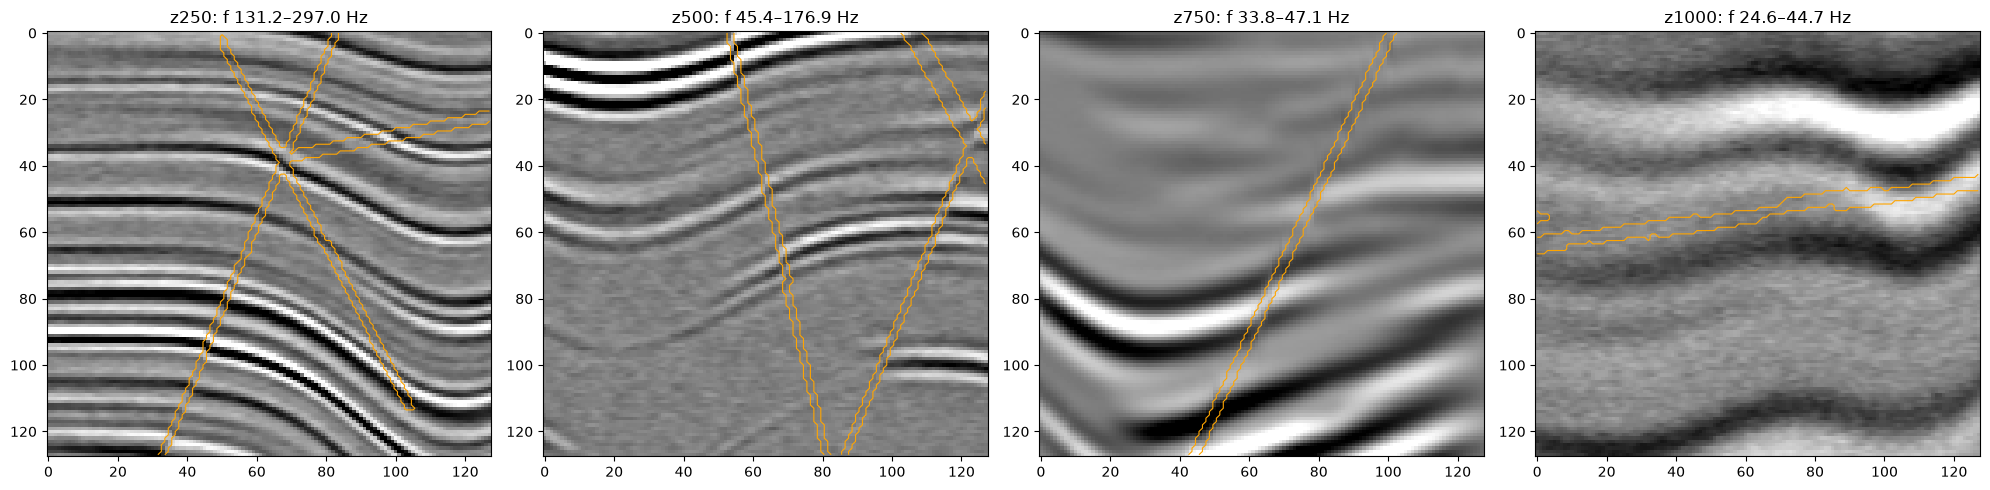

In [6]:
def getPreview(params, seed):
    np.random.seed(seed)
    generator = SyntheticGenerator(seed=seed)
    generator.set({**params, 'fast': True})
    image, mask = generator.get()
    image       = np.transpose(generator.applyGain(image), (0, 2, 1))
    return image, np.transpose(mask, (0, 2, 1))


fig, axes = plt.subplots(1, len(regions), figsize=(5 * len(regions), 5))
for i, (ax, (name, region)) in enumerate(zip(np.atleast_1d(axes), regions.items())):
    image, mask = getPreview(region['params'], SEED + i)
    ax.imshow(image[64], cmap='gray', aspect='auto')
    ax.contour(mask[64], levels=[0.5], colors='orange', linewidths=0.8)
    ax.set_title(f"{name}: f {region['params']['waveletFreq'][0]}–{region['params']['waveletFreq'][1]} Hz")
plt.tight_layout()
plt.show()

# CONFIGURAÇÃO MEDIDA
- A parte medida fica em `files/<bloco>/measured.json` no formato do `options` do `dataset()` (`seed` + `regions`): é o ponto de partida (`mean`) da busca e o candidato sem busca
- Para conferir a tradução, a tabela compara com o `C3_m4full`, montado à mão em 22/10 com as mesmas medidas

In [7]:
measured = {'seed': SEED, 'regions': regions}
json.dump(measured, open(f'{OUTPUT}/measured.json', 'w'), indent=1)

c3   = json.load(open('files/experiments/datasets/specs.json'))['C3_m4full']['regions']
keys = ['n_images', 'waveletFreq', 'seafloorProb', 'deadZoneProb']
pd.DataFrame({(name, quem): [str(r.get(k, r['params'].get(k))) for k in keys] for name in regions for quem, r in (('medido', regions[name]), ('C3', c3.get(name, {'params': {}})))}, index=keys).T

n_images     waveletFreq seafloorProb deadZoneProb
z250  medido       66  (131.2, 297.0)         0.32         0.05
      C3           66  [131.2, 297.0]          0.3          0.0
z500  medido       52   (45.4, 176.9)         0.05         0.17
      C3           52   [45.4, 176.9]         0.05          0.1
z750  medido       64    (33.8, 47.1)         0.05         0.19
      C3           64    [33.8, 47.1]         0.05         0.15
z1000 medido       38    (24.6, 44.7)         0.05         0.43
      C3           38    [24.6, 44.7]         0.05          0.5